In [63]:
import numpy as np, matplotlib.pyplot as plt, os
import matplotlib.gridspec as gridspec
import matplotlib.ticker as plticker
from matplotlib.colors import LinearSegmentedColormap
import matplotlib.cm as cm

import pandas as pd
from scipy.integrate import quadrature
from sklearn.metrics import matthews_corrcoef, r2_score

from glob import glob
from tqdm import tqdm

import tools21cm as t2c

plt.rcParams['font.size'] = 12
plt.rcParams['axes.linewidth'] = 1.1
plt.rcParams['xtick.direction'] = 'in'
plt.rcParams['ytick.direction'] = 'in'
plt.rcParams['xtick.top'] = False
plt.rcParams['ytick.right'] = True

169
78
128
119


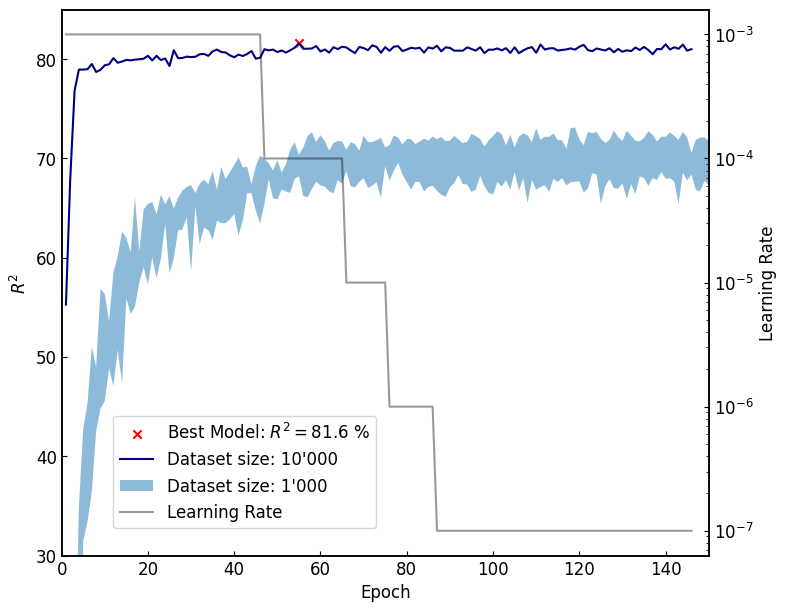

(None, None)

<Figure size 640x480 with 0 Axes>

In [147]:
#loss_files = glob('./sample_1000_150/val_loss*')
#loss_paper = np.loadtxt('val_loss_ep-146.txt')
loss_files = glob('./sample_1000_150/val_r2*')
loss_paper = np.loadtxt('val_r2score_ep-146.txt')
lr = np.loadtxt('lr_ep-146.txt')

idx_best_mode = np.argmax(loss_paper)


max_loss = np.zeros(180)
min_loss = np.zeros(180)

fig = plt.figure(figsize=(16, 6))
fig.subplots_adjust(hspace=0.3, wspace=0.25, top=0.99, bottom=0.08, right=0.955, left=0.045)
ax1 = plt.subplot(1,2,1)

for i, fname in enumerate(loss_files):
    loss = np.loadtxt(fname)
    
    idx_best = np.argmax(loss)+1
    #ax1.vlines(x=idx_best, ymin=0, ymax=1, color='tab:blue', alpha=0.4, ls='--')
    print(idx_best)

    if(i == 0):
        min_loss[:loss.size] = loss
        max_loss[:loss.size] = loss
    else: 
        for j in range(loss.size):
            min_loss[j] = np.min([loss[j], min_loss[j]])
            max_loss[j] = np.max([loss[j], max_loss[j]])

max_loss = max_loss[min_loss != 0.]
min_loss = min_loss[min_loss != 0.]

ax1.vlines(x=123.5, ymin=0, ymax=1, color='tab:blue', alpha=0.4, ls='--')

ax1.set_ylabel(r'$R^2$'), ax1.set_xlabel('Epoch')
ax1.scatter(idx_best_mode+1, loss_paper[idx_best_mode]*100, marker="x", color="r", label=r"Best Model: $R^2=$%.1f %%" %(100*loss_paper[idx_best_mode]))
ax1.plot(np.arange(loss_paper.size)+1, loss_paper*100, color='navy', label="Dataset size: 10'000", ls='-')

ax2 = ax1.twinx()
ax2.semilogy(np.arange(loss_paper.size)+1, lr, color='k', alpha=0.4, label='Learning Rate')
ax2.set_ylabel('Learning Rate')

#ax1.semilogy(np.arange(loss_paper.size)+1, loss_paper)
ax1.fill_between(x=np.arange(min_loss.size)+1, y1=min_loss*100, y2=max_loss*100, alpha=0.5, label="Dataset size: 1'000")
ax1.set_ylim(30, 85)
ax1.set_xlim(0, 150)

lns, labs   = ax1.get_legend_handles_labels()
lns2, labs2 = ax2.get_legend_handles_labels()
ax1.legend(lns+lns2, labs+labs2, loc=(0.08, 0.05))

#plt.savefig('compare_loss.png', bbox_inches='tight')
plt.show(), plt.clf()